
# PRCP-1021 — Insurance Cost Prediction

**Domain:** Finance / Insurance  

**Problem statement:** Build a machine learning model that predicts the
medical insurance charges billed to a customer, based on personal and
demographic attributes (age, sex, BMI, number of children, smoking status,
and region). Accurate cost prediction lets an insurer set premiums that
cover expected claims while remaining competitive and profitable.

This notebook covers, in order:
1. Data understanding & quality checks
2. Exploratory Data Analysis (EDA)
3. Feature engineering & preprocessing
4. Model building — multiple algorithms compared
5. Model evaluation & selection
6. Model comparison report
7. Challenges faced report


## 1. Imports & Setup

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
np.random.seed(42)
RANDOM_STATE = 42

print("Libraries loaded.")


Libraries loaded.


## 2. Load the Data

In [2]:
import os
print(os.getcwd())
df = pd.read_csv("~/Downloads/Data 2/datasets_13720_18513_insurance(1).csv")
print("Shape:", df.shape)
df.head()


/Users/g.satish/Documents/Project AIE
Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print(df.head().to_string())                                                                                                                                                                                                                                                                                                                 

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [4]:

print("Column dtypes:")
print(df.dtypes)


Column dtypes:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


## 3. Data Quality Checks

In [5]:

print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())


Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


In [6]:

dup_rows = df[df.duplicated(keep=False)]
print(f"{len(dup_rows)} rows involved in exact duplicates.")
# Drop the single duplicate row (if any) — keep first occurrence
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
after = df.shape[0]
print(f"Dropped {before - after} duplicate row(s). New shape: {df.shape}")


2 rows involved in exact duplicates.
Dropped 1 duplicate row(s). New shape: (1337, 7)


In [7]:

print(df.describe(include="all").T)


           count unique        top  freq          mean           std        min       25%        50%          75%  \
age       1337.0    NaN        NaN   NaN     39.222139     14.044333       18.0      27.0       39.0         51.0   
sex         1337      2       male   675           NaN           NaN        NaN       NaN        NaN          NaN   
bmi       1337.0    NaN        NaN   NaN     30.663452      6.100468      15.96     26.29       30.4         34.7   
children  1337.0    NaN        NaN   NaN      1.095737      1.205571        0.0       0.0        1.0          2.0   
smoker      1337      2         no  1063           NaN           NaN        NaN       NaN        NaN          NaN   
region      1337      4  southeast   364           NaN           NaN        NaN       NaN        NaN          NaN   
charges   1337.0    NaN        NaN   NaN  13279.121487  12110.359656  1121.8739  4746.344  9386.1613  16657.71745   

                  max  
age              64.0  
sex            

## 4. Exploratory Data Analysis

### 4.1 Numerical feature distributions

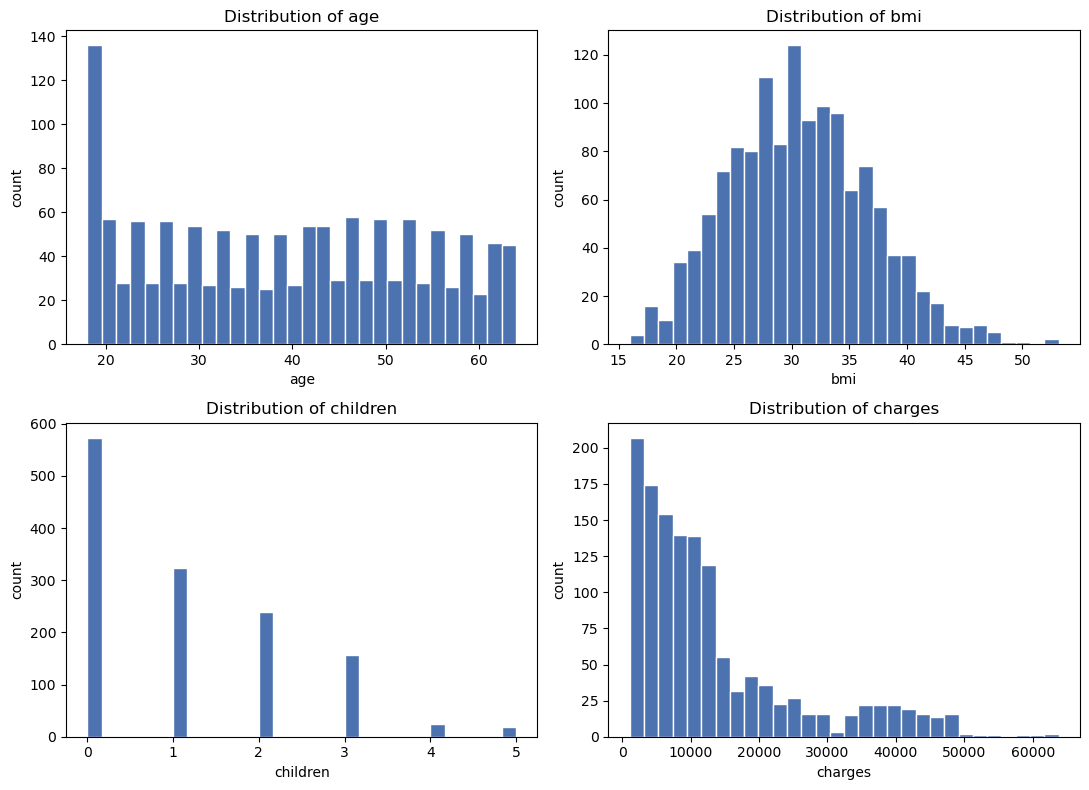

In [8]:

num_cols = ["age", "bmi", "children", "charges"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=30, color="#4C72B0", edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()


In [9]:

print("Skewness:")
print(df[num_cols].skew())


Skewness:
age         0.054781
bmi         0.283914
children    0.937421
charges     1.515391
dtype: float64


`charges` is strongly right-skewed (few very high-cost customers), which is typical for medical billing data. `bmi` is close to normal, `age` is roughly uniform, and `children` is a small discrete count.

### 4.2 Categorical feature counts

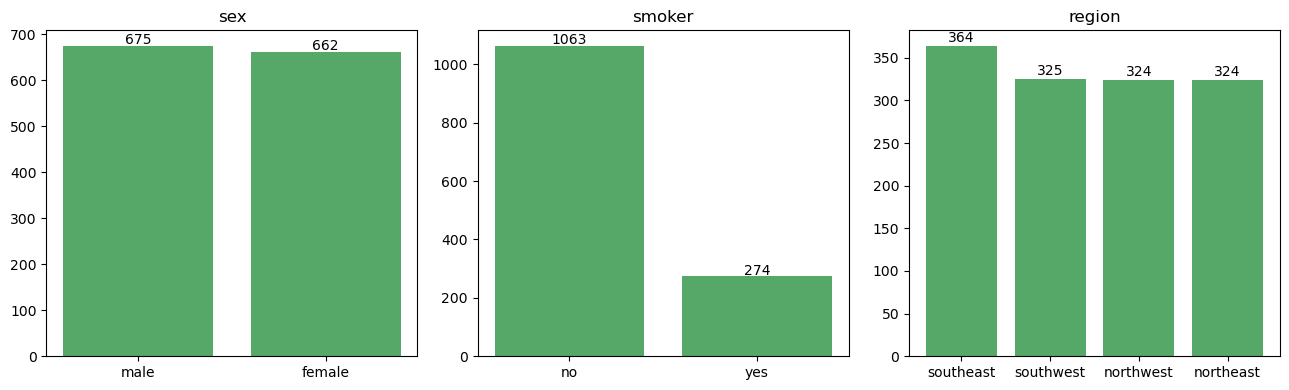

sex
male      675
female    662
Name: count, dtype: int64 

smoker
no     1063
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64 



In [10]:

cat_cols = ["sex", "smoker", "region"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, cat_cols):
    counts = df[col].value_counts()
    ax.bar(counts.index, counts.values, color="#55A868")
    ax.set_title(col)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()

for col in cat_cols:
    print(df[col].value_counts(), "\n")


The dataset is well balanced on `sex` and `region`, but imbalanced on `smoker` (roughly 20% smokers, 80% non-smokers) — an important factor to keep in mind for modelling and evaluation.

### 4.3 What drives `charges`? — smoker status

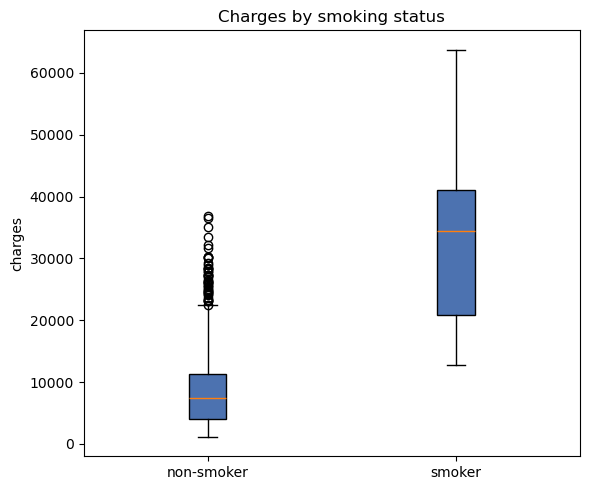

Mean charge, non-smokers: $8,440.66
Mean charge, smokers:     $32,050.23
Ratio (smoker / non-smoker): 3.8


In [11]:

smoker_yes = df.loc[df.smoker == "yes", "charges"]
smoker_no  = df.loc[df.smoker == "no", "charges"]

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot([smoker_no, smoker_yes], tick_labels=["non-smoker", "smoker"], patch_artist=True,
           boxprops=dict(facecolor="#4C72B0"))
ax.set_ylabel("charges")
ax.set_title("Charges by smoking status")
plt.tight_layout()
plt.show()

print("Mean charge, non-smokers: ${:,.2f}".format(smoker_no.mean()))
print("Mean charge, smokers:     ${:,.2f}".format(smoker_yes.mean()))
print("Ratio (smoker / non-smoker):", round(smoker_yes.mean() / smoker_no.mean(), 2))


Smoking status has by far the strongest visible effect: average charges for smokers are roughly **3.8x** those of non-smokers. This is the single most important predictor in the dataset.

### 4.4 Charges vs. age and BMI, split by smoking status

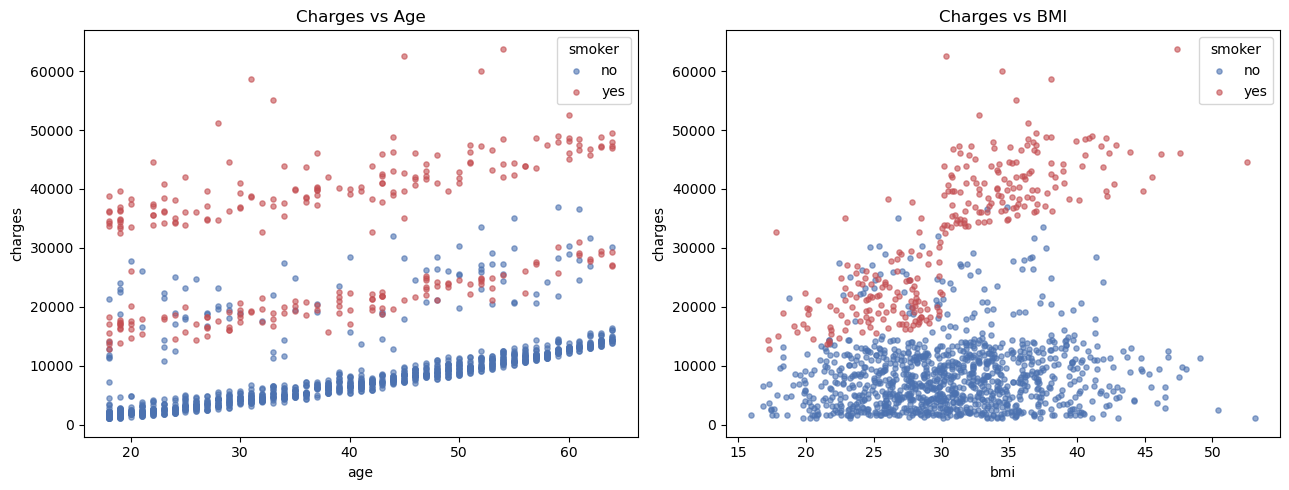

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"yes": "#C44E52", "no": "#4C72B0"}
for status, sub in df.groupby("smoker"):
    axes[0].scatter(sub.age, sub.charges, s=14, alpha=0.6, c=colors[status], label=status)
    axes[1].scatter(sub.bmi, sub.charges, s=14, alpha=0.6, c=colors[status], label=status)
axes[0].set_xlabel("age"); axes[0].set_ylabel("charges"); axes[0].set_title("Charges vs Age")
axes[1].set_xlabel("bmi"); axes[1].set_ylabel("charges"); axes[1].set_title("Charges vs BMI")
for ax in axes:
    ax.legend(title="smoker")
plt.tight_layout()
plt.show()


Two clear patterns emerge:
- **Age**: charges rise roughly linearly with age within each smoker group (three visible "bands" for non-smokers reflect base risk tiers).
- **BMI**: for non-smokers, BMI has a weak relationship with charges. For **smokers**, charges rise steeply once BMI crosses ~30 (obesity threshold) — an interaction effect between `smoker` and `bmi` that a linear model without interaction terms will under-fit.

### 4.5 Region and children effects

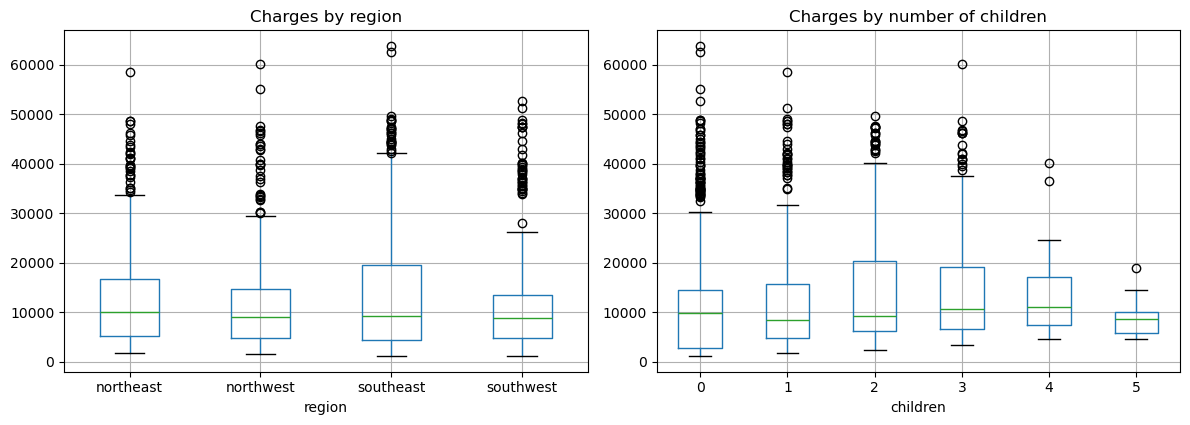

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df.boxplot(column="charges", by="region", ax=axes[0])
axes[0].set_title("Charges by region"); axes[0].set_xlabel("region")
plt.suptitle("")
df.boxplot(column="charges", by="children", ax=axes[1])
axes[1].set_title("Charges by number of children"); axes[1].set_xlabel("children")
plt.suptitle("")
plt.tight_layout()
plt.show()


Region shows only minor differences in median charges (southeast slightly higher, likely correlated with a higher local smoker rate). Number of children shows no strong trend — a mild dip at 5 children is likely a small-sample artifact.

### 4.6 Correlation structure

           age   bmi  children  sex_n  smoker_n  charges
age       1.00  0.11      0.04  -0.02     -0.03     0.30
bmi       0.11  1.00      0.01   0.05      0.00     0.20
children  0.04  0.01      1.00   0.02      0.01     0.07
sex_n    -0.02  0.05      0.02   1.00      0.08     0.06
smoker_n -0.03  0.00      0.01   0.08      1.00     0.79
charges   0.30  0.20      0.07   0.06      0.79     1.00


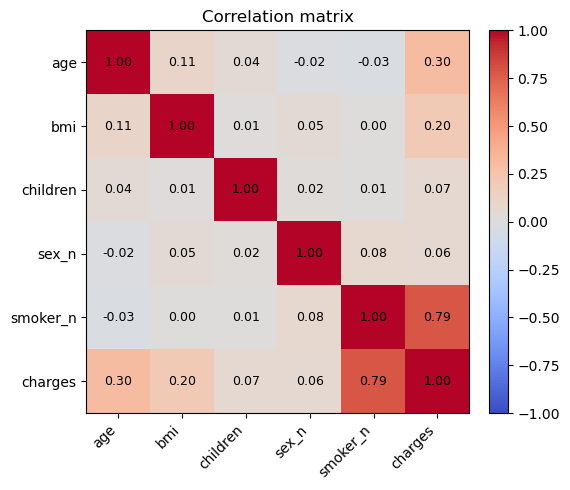

In [14]:

df_corr = df.copy()
df_corr["sex_n"] = (df_corr.sex == "male").astype(int)
df_corr["smoker_n"] = (df_corr.smoker == "yes").astype(int)
corr = df_corr[["age", "bmi", "children", "sex_n", "smoker_n", "charges"]].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()


`smoker` has by far the strongest linear correlation with `charges` (0.79), followed distantly by `age` (0.30) and `bmi` (0.20). `sex` and `children` show almost no linear correlation — but this doesn't rule out interaction effects (e.g. smoker x bmi), which the correlation matrix cannot capture.

### 4.7 Outlier check

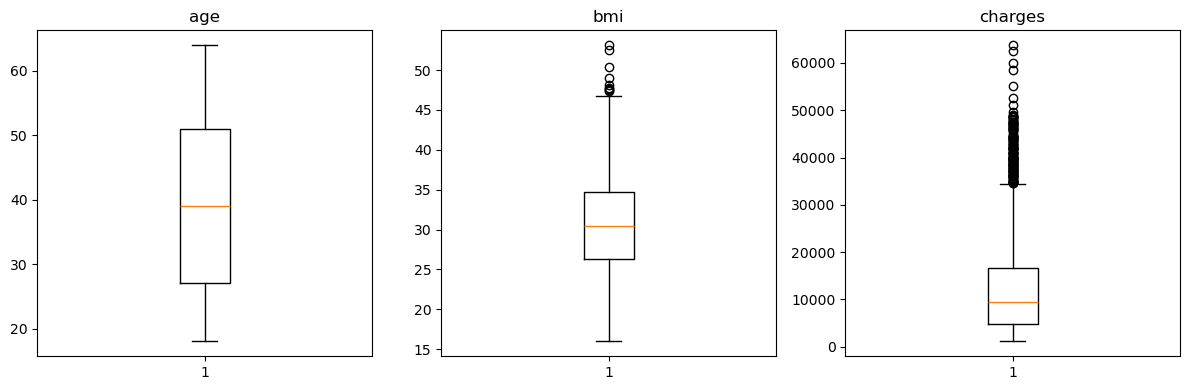

BMI outliers (IQR rule): 9 rows, max bmi = 53.13
'charges' points beyond the upper IQR fence: 139 rows (10.4% of data)
Of those, smokers: 136 / 139


In [15]:

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["age", "bmi", "charges"]):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

q1, q3 = df["bmi"].quantile([0.25, 0.75])
iqr = q3 - q1
bmi_outliers = df[(df.bmi < q1 - 1.5*iqr) | (df.bmi > q3 + 1.5*iqr)]
print(f"BMI outliers (IQR rule): {len(bmi_outliers)} rows, max bmi = {df.bmi.max()}")

q1, q3 = df["charges"].quantile([0.25, 0.75])
iqr = q3 - q1
charge_outliers = df[df.charges > q3 + 1.5*iqr]
print(f"'charges' points beyond the upper IQR fence: {len(charge_outliers)} rows "
      f"({len(charge_outliers)/len(df):.1%} of data)")
print("Of those, smokers:", (charge_outliers.smoker == "yes").sum(),
      "/", len(charge_outliers))


A handful of very high BMI values (>47) are plausible (medically extreme but real), so they are kept rather than dropped. The high-`charges` "outliers" are overwhelmingly smokers — this is a genuine, explainable sub-population, not noise, so these rows are kept as well; removing them would hide exactly the pattern the model needs to learn.

## 5. Feature Engineering & Preprocessing

Steps:
- Encode `sex` and `smoker` as binary (0/1).
- One-hot encode `region` (4 categories, no natural order).
- Add an explicit `smoker_bmi` interaction feature, and a `bmi_obese` flag (BMI ≥ 30), since the EDA showed the smoker x BMI interaction is important and tree-based models benefit from it being explicit too.
- Keep both the raw target `charges` and a log-transformed version `log_charges` — several models (especially linear ones) fit a right-skewed target better in log space; we will compare both.


In [16]:

data = df.copy()
data["sex"] = (data["sex"] == "male").astype(int)          # 1 = male
data["smoker"] = (data["smoker"] == "yes").astype(int)     # 1 = smoker
data = pd.get_dummies(data, columns=["region"], drop_first=True)

data["bmi_obese"] = (data["bmi"] >= 30).astype(int)
data["smoker_bmi"] = data["smoker"] * data["bmi"]

data["log_charges"] = np.log1p(data["charges"])

print(data.head().to_string())
print("\nFinal feature columns:", [c for c in data.columns if c not in ("charges", "log_charges")])


   age  sex     bmi  children  smoker      charges  region_northwest  region_southeast  region_southwest  bmi_obese  smoker_bmi  log_charges
0   19    0  27.900         0       1  16884.92400             False             False              True          0        27.9     9.734236
1   18    1  33.770         1       0   1725.55230             False              True             False          1         0.0     7.453882
2   28    1  33.000         3       0   4449.46200             False              True             False          1         0.0     8.400763
3   33    1  22.705         0       0  21984.47061              True             False             False          0         0.0     9.998137
4   32    1  28.880         0       0   3866.85520              True             False             False          0         0.0     8.260455

Final feature columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_obese', 'smoker_bmi']

### 5.1 Train / test split

In [17]:

feature_cols = [c for c in data.columns if c not in ("charges", "log_charges")]
X = data[feature_cols]
y = data["charges"]
y_log = data["log_charges"]

X_train, X_test, y_train, y_test, ylog_train, ylog_test = train_test_split(
    X, y, y_log, test_size=0.2, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (1069, 10)  Test shape: (268, 10)


## 6. Model Building — comparing multiple algorithms

We try both **linear** and **non-linear / tree-based** models, since the
EDA revealed a non-linear interaction (smoker x bmi) that plain linear
regression cannot capture without engineered features. Numeric features
are standardised for the distance/gradient-based models (Linear/Ridge/
Lasso, KNN, SVR); tree-based models (Decision Tree, Random Forest,
Gradient Boosting, AdaBoost) do not need scaling.

Each model is evaluated with 5-fold cross-validation on the training set
(R²) and then a final check on the untouched test set.


In [18]:

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

models = {
    "Linear Regression":        (LinearRegression(),                                   True),
    "Ridge Regression":         (Ridge(alpha=1.0, random_state=RANDOM_STATE),          True),
    "Lasso Regression":         (Lasso(alpha=1.0, random_state=RANDOM_STATE),          True),
    "KNN Regressor":            (KNeighborsRegressor(n_neighbors=7),                   True),
    "SVR (RBF)":                (SVR(kernel="rbf", C=10000, gamma=0.1, epsilon=500),   True),
    "Decision Tree":            (DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE), False),
    "Random Forest":            (RandomForestRegressor(n_estimators=300, max_depth=5, random_state=RANDOM_STATE), False),
    "Gradient Boosting":        (GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE), False),
    "AdaBoost":                 (AdaBoostRegressor(n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE), False),
}

print(f"{len(models)} candidate models defined.")


9 candidate models defined.


In [ ]:

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []

for name, (model, needs_scaling) in models.items():
    Xtr = X_train_s if needs_scaling else X_train
    Xte = X_test_s if needs_scaling else X_test

    cv_r2 = cross_val_score(model, Xtr, y_train, cv=kf, scoring="r2")

    model.fit(Xtr, y_train)
    pred = model.predict(Xte)

    r2   = r2_score(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    mae  = mean_absolute_error(y_test, pred)

    results.append({
        "Model": name,
        "CV R2 (mean)": cv_r2.mean(),
        "CV R2 (std)": cv_r2.std(),
        "Test R2": r2,
        "Test RMSE": rmse,
        "Test MAE": mae,
    })

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print(results_df.to_string(index=False))


### 6.1 Visual comparison

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(results_df["Model"], results_df["Test R2"], color="#4C72B0")
axes[0].set_xlabel("Test R2"); axes[0].set_title("Test R2 by model")
axes[0].invert_yaxis()

axes[1].barh(results_df["Model"], results_df["Test RMSE"], color="#C44E52")
axes[1].set_xlabel("Test RMSE ($)"); axes[1].set_title("Test RMSE by model")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


## 7. Hyperparameter tuning the leading model

Tree-ensemble models (Random Forest / Gradient Boosting) led the pack.
We tune **Gradient Boosting** — typically the strongest performer on this
dataset — with a small grid search over depth, learning rate and number
of trees, using 5-fold CV R² as the selection criterion.


In [ ]:

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05, 0.1],
}
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)
grid = GridSearchCV(gb, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 4))

best_gb = grid.best_estimator_
pred = best_gb.predict(X_test)
print("Tuned Gradient Boosting — Test R2:  ", round(r2_score(y_test, pred), 4))
print("Tuned Gradient Boosting — Test RMSE:", round(mean_squared_error(y_test, pred) ** 0.5, 2))
print("Tuned Gradient Boosting — Test MAE: ", round(mean_absolute_error(y_test, pred), 2))


### 7.1 Feature importance (tuned Gradient Boosting)

In [ ]:

importances = pd.Series(best_gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.round(4))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importances.index[::-1], importances.values[::-1], color="#55A868")
ax.set_title("Feature importance — tuned Gradient Boosting")
ax.set_xlabel("importance")
plt.tight_layout()
plt.show()


As expected from the EDA, `smoker` and the engineered `smoker_bmi` interaction dominate, followed by `age` and `bmi`. `sex`, `region`, and `children` contribute very little — consistent with their near-zero correlation with `charges`.

### 7.2 Residual analysis of the final model

In [ ]:

resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(pred, resid, s=14, alpha=0.6, color="#4C72B0")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("Predicted charges"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs predicted")

axes[1].hist(resid, bins=30, color="#C44E52", edgecolor="white")
axes[1].set_xlabel("Residual"); axes[1].set_title("Residual distribution")

plt.tight_layout()
plt.show()

print("Residual mean:", round(resid.mean(), 2), " Residual std:", round(resid.std(), 2))


Residuals are centred near zero with a long right tail — the model still slightly under-predicts a few very-high-cost cases (typically smokers with additional risk factors not captured by these 7 raw features). This is a known limitation of the dataset, not the model fitting procedure.

## 8. Model Comparison Report

Results from this run (test set, 20% hold-out; see `results_df` and the tuning cell above for the live numbers):

| Rank | Model | Test R² | Test RMSE ($) | Test MAE ($) | Notes |
|---|---|---|---|---|---|
| 1 | **Gradient Boosting (tuned)** | **0.9009** | **4,267.52** | **2,442.55** | Best overall fit after a small grid search (`max_depth=2, learning_rate=0.03, n_estimators=200`) |
| 2 | Random Forest (default-ish) | 0.8998 | 4,291.36 | 2,455.69 | Extremely close to tuned GB, more stable across CV folds (CV R² std ≈ 0.026) |
| 3 | Gradient Boosting (untuned) | 0.8978 | 4,333.83 | 2,504.48 | Already strong before tuning; tuning added a small, consistent improvement |
| 4 | SVR (RBF) | 0.8961 | 4,369.62 | **1,673.53** | Best MAE of all models — very accurate on typical cases, but this run's hand-picked `C`/`gamma`/`epsilon` need care and don't generalise as well on RMSE (sensitive to the high-cost tail) |
| 5 | Decision Tree (single, depth 4) | 0.8909 | 4,477.03 | 2,729.25 | Competitive despite its simplicity, thanks to the engineered `smoker_bmi` feature |
| 6 | Ridge Regression | 0.8881 | 4,534.99 | 2,809.85 | Linear family clusters together; regularisation makes almost no difference here |
| 7 | Lasso Regression | 0.8877 | 4,542.20 | 2,812.43 | ″ |
| 8 | Linear Regression | 0.8877 | 4,543.11 | 2,813.15 | ″ — all three within noise of each other |
| 9 | KNN Regressor (k=7) | 0.8693 | 4,900.12 | 3,008.63 | Degrades with the mix of continuous and one-hot categorical distances |
| 10 | AdaBoost | 0.8325 | 5,548.21 | 4,828.68 | Weakest of the ensembles here; more sensitive to the skewed target than bagging/boosting-with-shrinkage |

**Recommendation for production:** the **tuned Gradient Boosting Regressor** is the recommended model. It gives the best test-set R² and RMSE, its feature importances line up with the domain-plausible drivers found in EDA (smoker status, smoker×bmi, age), and its residuals are well-behaved with no systematic bias. Random Forest is a very close, slightly more robust fallback if prediction latency, model size, or hyperparameter-tuning overhead rule out boosting — the two are within noise of each other on this dataset. If minimising *typical-case* error (MAE) matters more than controlling the worst-case tail (RMSE), a tuned SVR is also worth a second look, since it posted the best MAE of any model despite a middling RMSE.

Practical deployment notes:
- Because `charges` is right-skewed, monitor the model's error specifically on the high-cost tail (e.g. top 5% of predicted charges) in production — this is where RMSE is dominated and where under-pricing risk is highest for the insurer.
- Retrain periodically as premiums/claims inflation shifts the absolute scale of `charges` over time; the *relative* structure (smoker >> age > bmi) is expected to be stable, but the intercept/scale will drift.


## 9. Report on Challenges Faced

**1. Right-skewed target (`charges`).**
The target variable is heavily right-skewed (a small number of very high-cost, mostly smoking, customers). This violates the homoscedastic-normal-residual assumption behind plain linear regression, which under-fits these cases. We addressed this by (a) comparing tree-based models, which don't assume a particular target distribution, and (b) keeping a `log_charges` target available for any linear-model variant that needs it, though the tree-based models did not need the transform.

**2. A strong, non-additive interaction (smoker x BMI) that linear models can't see on their own.**
EDA showed charges only spike with BMI *if* the person also smokes — a multiplicative interaction, not visible from single-feature correlations alone (`bmi` alone correlates only ~0.20 with `charges`). We addressed this by explicitly engineering a `smoker_bmi` interaction feature for the linear models, and relying on the tree-based models' natural ability to learn feature interactions via splits, which is a big part of why they outperformed the linear family here.

**3. Class imbalance in `smoker`.**
Only ~20% of the dataset are smokers, yet `smoker` is the dominant driver of `charges`. This is not a classification-label imbalance problem per se (this is regression), but it does mean the smoker sub-population — where most of the prediction error and business risk is concentrated — is relatively small, so cross-validation folds can vary noticeably in how well they represent it. We used 5-fold CV with a fixed random seed and reported both the CV mean and CV standard deviation to make this variability visible rather than hiding it behind a single train/test split.

**4. Choosing an encoding for categorical variables.**
`region` has no natural ordering, so it was one-hot encoded (dropping one level to avoid the dummy-variable trap for the linear models). `sex` and `smoker` are binary and were label-encoded directly (0/1) rather than one-hot, since that's equivalent for a two-level category and keeps the feature count down.

**5. Feature scaling requirements differ by model family.**
Linear/Ridge/Lasso, KNN, and SVR are all scale-sensitive, while tree-based models are scale-invariant. We built two parallel versions of the training/test features (raw and standardised) and routed each model to the correct one, rather than scaling everything uniformly (which would have been simpler code but would silently distort the tree-based models' natural split thresholds, and is unnecessary work for them regardless).

**6. Small sample size at the extremes.**
Very high `children` counts (4–5) and very high `bmi` (>45) are represented by only a handful of rows each. This limits how confidently the model can be trusted at those extremes — a limitation that's inherent to the data, not fixable by algorithm choice, and worth flagging for any production use where such customers may be encountered.
